# data audit


In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
data= pd.read_csv('Housing.csv')
data.head(10)

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished
5,10850000,7500,3,3,1,yes,no,yes,no,yes,2,yes,semi-furnished
6,10150000,8580,4,3,4,yes,no,no,no,yes,2,yes,semi-furnished
7,10150000,16200,5,3,2,yes,no,no,no,no,0,no,unfurnished
8,9870000,8100,4,1,2,yes,yes,yes,no,yes,2,yes,furnished
9,9800000,5750,3,2,4,yes,yes,no,no,yes,1,yes,unfurnished


In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingstatus  545 non-null    object
dtypes: int64(6), object(7)
memory usage: 55.5+ KB


In [4]:
data.shape

(545, 13)

In [5]:
data.describe()

,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


In [6]:
data.isnull().sum()

,0
price,0
area,0
bedrooms,0
bathrooms,0
stories,0
mainroad,0
guestroom,0
basement,0
hotwaterheating,0
airconditioning,0


In [7]:
data.duplicated().sum()

np.int64(0)

In [8]:
data['furnishingstatus'].unique()

array(['furnished', 'semi-furnished', 'unfurnished'], dtype=object)

In [9]:
data.describe(include='O')

,mainroad,guestroom,basement,hotwaterheating,airconditioning,prefarea,furnishingstatus
count,545,545,545,545,545,545,545
unique,2,2,2,2,2,2,3
top,yes,no,no,no,no,no,semi-furnished
freq,468,448,354,520,373,417,227


In [10]:
data['price'].skew()  #Right Skewness

np.float64(1.2122388370279802)

In [11]:
data.value_counts()

price     area  bedrooms  bathrooms  stories  mainroad  guestroom  basement  hotwaterheating  airconditioning  parking  prefarea  furnishingstatus
1750000   2910  3         1          1        no        no         no        no               no               0        no        furnished           1
          3620  2         1          1        yes       no         no        no               no               0        no        unfurnished         1
          3850  3         1          2        yes       no         no        no               no               0        no        unfurnished         1
1767150   2400  3         1          1        no        no         no        no               no               0        no        semi-furnished      1
1820000   3000  2         1          1        yes       no         yes       no               no               2        no        unfurnished         1
                                                                                                                                                     ..
11410000  7420  4         1          2        yes       yes        yes       no               yes              2        no        furnished           1
12215000  7500  4         2          2        yes       no         yes       no               yes              3        yes       furnished           1
12250000  8960  4         4          4        yes       no         no        no               yes              3        no        furnished           1
          9960  3         2          2        yes       no         yes       no               no               2        yes       semi-furnished      1
13300000  7420  4         2          3        yes       no         no        no               yes              2        yes       furnished           1
Name: count, Length: 545, dtype: int64

In [12]:
data.nlargest(5, "area")

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
7,10150000,16200,5,3,2,yes,no,no,no,no,0,no,unfurnished
125,5943000,15600,3,1,1,yes,no,no,no,yes,2,no,semi-furnished
10,9800000,13200,3,1,2,yes,no,yes,no,yes,2,yes,furnished
66,6930000,13200,2,1,1,yes,no,yes,yes,no,1,no,furnished
403,3500000,12944,3,1,1,yes,no,no,no,no,0,no,unfurnished


#Explore each feature


In [13]:
data.columns

Index(['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad',
       'guestroom', 'basement', 'hotwaterheating', 'airconditioning',
       'parking', 'prefarea', 'furnishingstatus'],
      dtype='object')

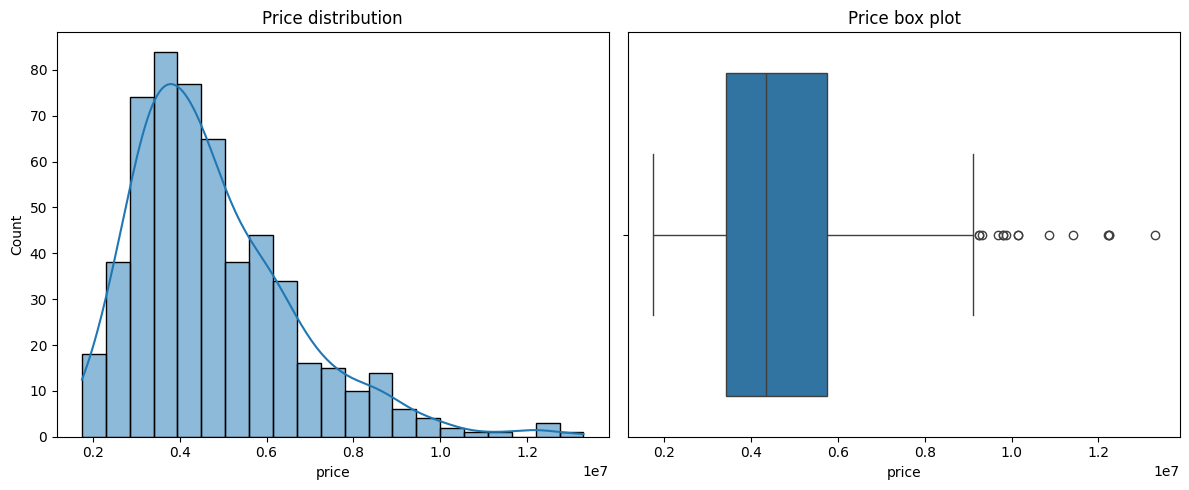

Price IQR upper fence: 9205000.0 | rows above: 15


In [14]:
# SHOW PRICE DISTRIBUTION
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(data.price, kde=True, ax=ax[0])
ax[0].set_title('Price distribution')
sns.boxplot(x=data.price, ax=ax[1])
ax[1].set_title('Price box plot')
plt.tight_layout()
plt.show()
q1, q3 = data.price.quantile([.25, .75])
print('Price IQR upper fence:', q3 + 1.5 * (q3 - q1), '| rows above:', (data.price > q3 + 1.5 * (q3 - q1)).sum())

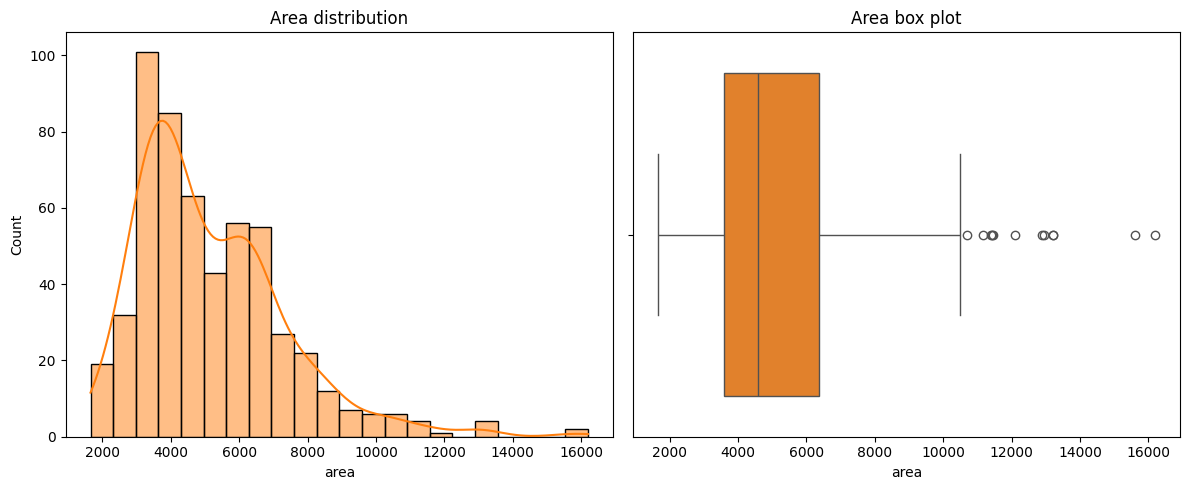

Area IQR upper fence: 10500.0 | rows above: 12


In [15]:
# SHOW AREA DISTRIBUTION
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(data.area, kde=True, ax=ax[0], color='tab:orange')
ax[0].set_title('Area distribution')
sns.boxplot(x=data.area, ax=ax[1], color='tab:orange')
ax[1].set_title('Area box plot')
plt.tight_layout()
plt.show()
q1,q3=data.area.quantile([.25,.75]); print('Area IQR upper fence:', q3+1.5*(q3-q1), '| rows above:', (data.area>q3+1.5*(q3-q1)).sum())

Price is right-skewed with a long upper tail; the box plot flags 15 houses above the IQR fence (≈ 9.2M). Area is also right-skewed, with 12 plots above its fence (≈ 10,500). These are plausible real-world values (large or luxury properties), not data errors, so they are **kept**. The skew matters later: a linear model on raw price may under-predict expensive houses, which is tested in the log-target experiment.

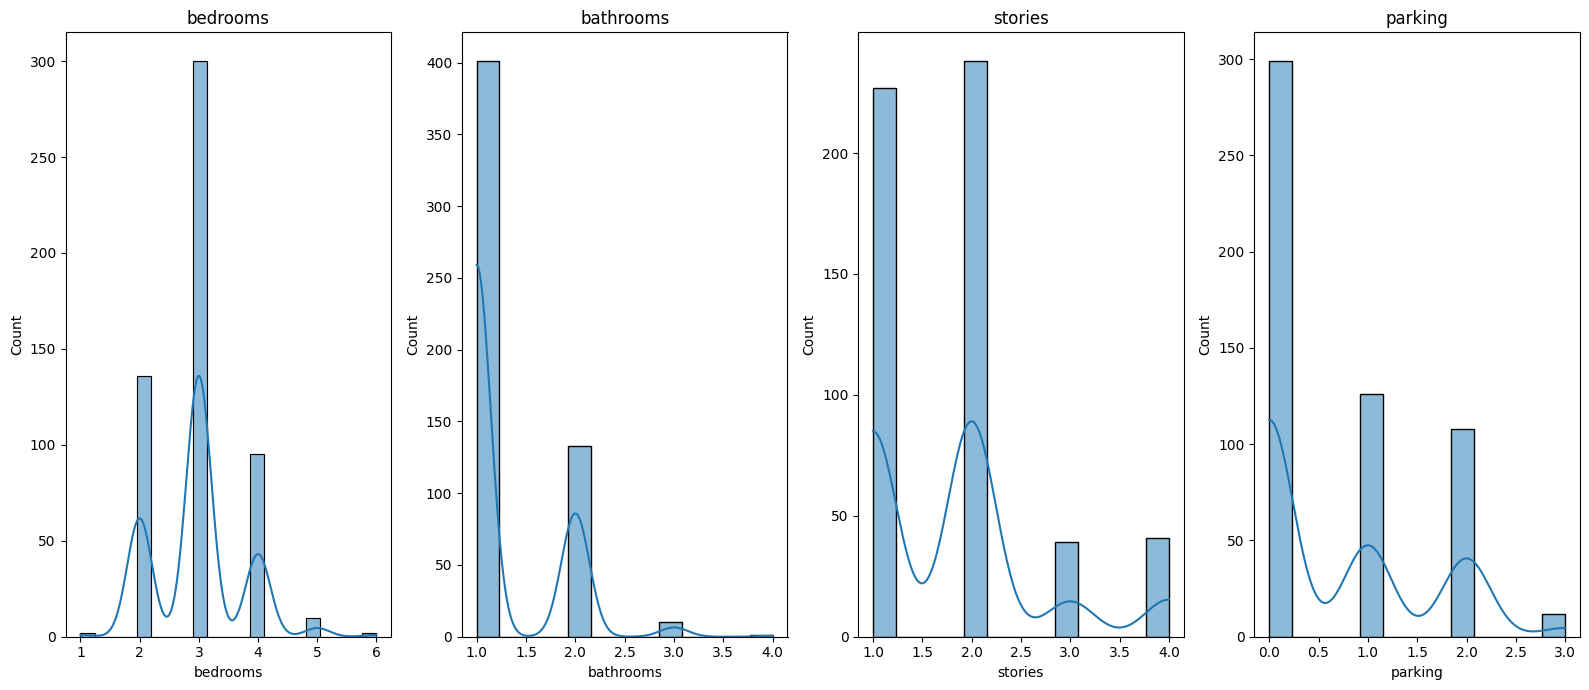

In [16]:
# DISPLAY DISCREETE NUMERICAL VALUE
num_cols = ["bedrooms", "bathrooms", "stories", "parking"]
fig, axes = plt.subplots(1, 4, figsize=(16, 7))
for ax, c in zip(axes.ravel(), num_cols):
    sns.histplot(data[c], kde=True, ax=ax)
    ax.set_title(c)
plt.tight_layout(); plt.show()

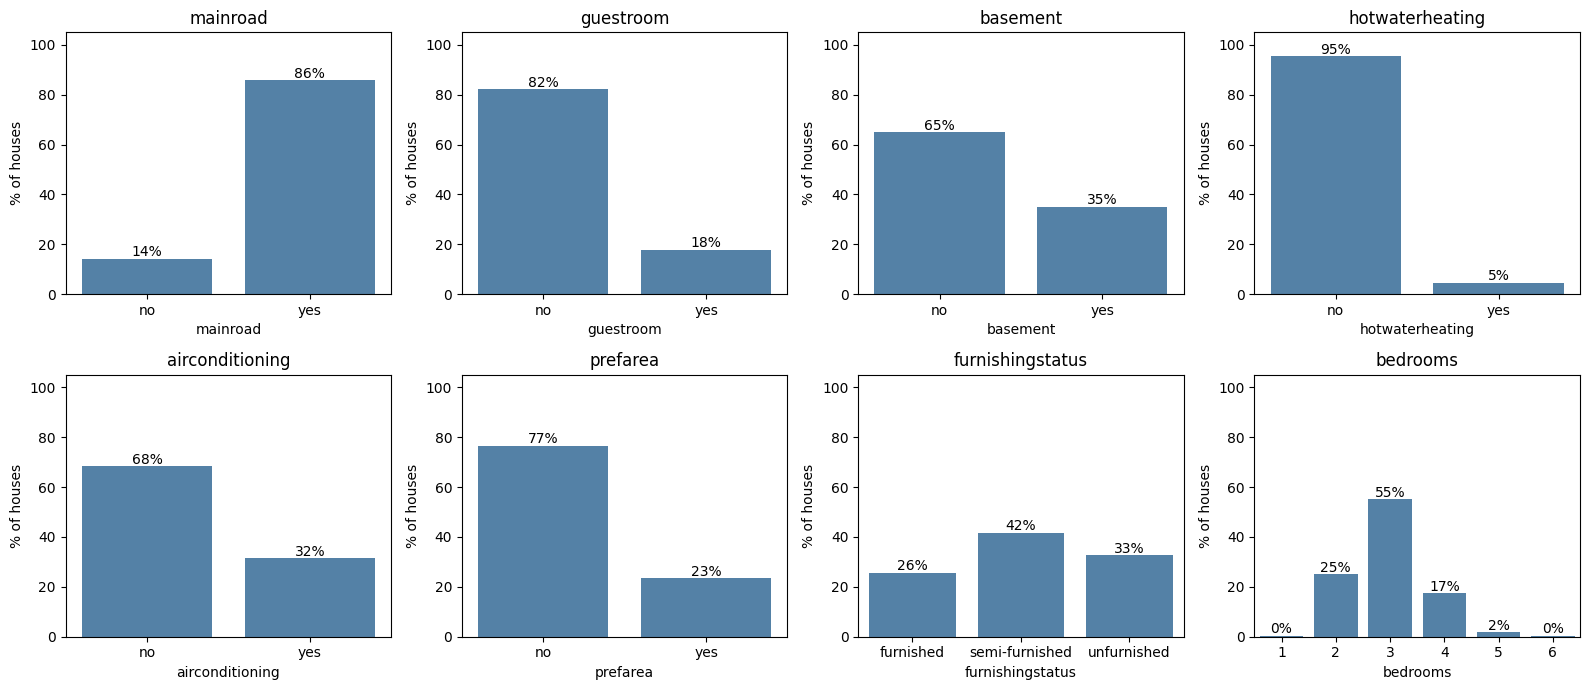

In [16]:
# DISCRETE COUNTS AND YES/NO FEATURES WITH PERSECENTAGES
categorical_cols = ["mainroad", "guestroom", "basement", "hotwaterheating", "airconditioning", "prefarea", "furnishingstatus"]
fig, axes = plt.subplots(2,4, figsize=(16,7)); axes=axes.ravel()
for a,c in zip(axes, categorical_cols+['bedrooms']):
    pct = data[c].value_counts(normalize=True).sort_index()*100
    sns.barplot(x=pct.index.astype(str), y=pct.values, ax=a, color='steelblue')
    for i,v in enumerate(pct.values): a.text(i, v+1, f'{v:.0f}%', ha='center')
    a.set_title(c)
    a.set_ylabel('% of houses')
    a.set_ylim(0,105)

plt.tight_layout()
plt.show()

Classes are unbalanced: 86% of houses are on a main road, only 5% have hot-water heating (25 houses) and 18% have a guest room. Any conclusion about `hotwaterheating` rests on very few rows and should be treated cautiously. 3-bedroom houses dominate (55%); 1- and 6-bedroom houses have only 2 rows each, so the extremes of `bedrooms` are poorly sampled.

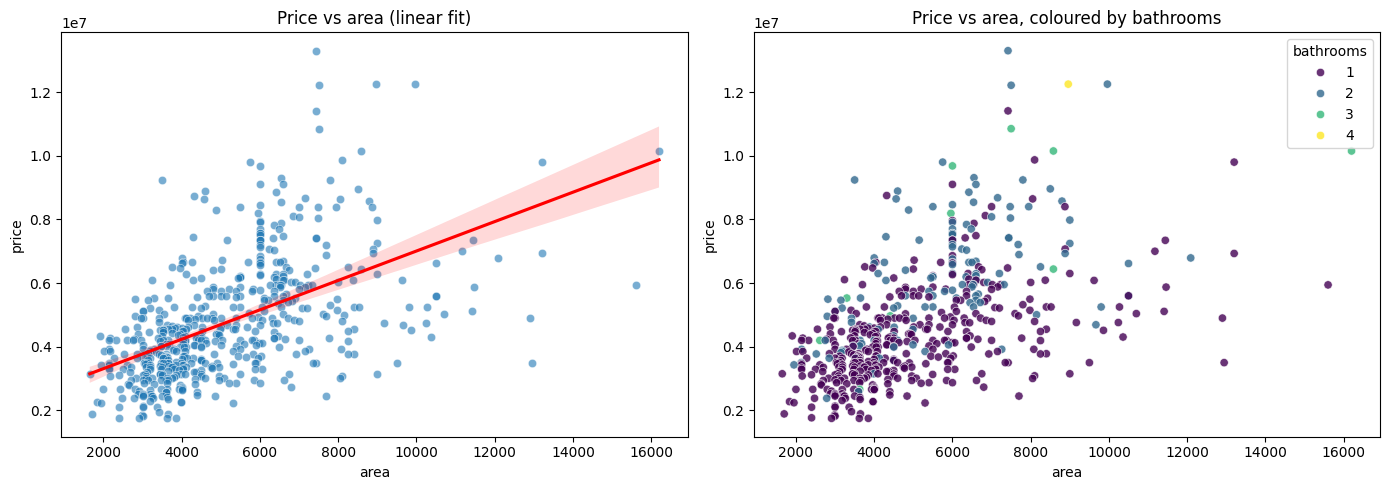

Correlation between price and area: 0.5359973457780796


In [17]:
#How does price relate to area and to the other numeric features?

fig, ax = plt.subplots(1,2, figsize=(14,5))
sns.scatterplot(data=data, x='area', y='price', alpha=.6, ax=ax[0])
sns.regplot(data=data, x='area', y='price', scatter=False, color='red', ax=ax[0])
ax[0].set_title('Price vs area (linear fit)')
sns.scatterplot(data=data, x='area', y='price', hue='bathrooms', palette='viridis', alpha=.8, ax=ax[1])
ax[1].set_title('Price vs area, coloured by bathrooms')
plt.tight_layout()
plt.show()
print('Correlation between price and area:', data.price.corr(data.area))

Price rises with area (r ≈ 0.54), roughly linearly but with a lot of scatter and a funnel shape: spread grows with area. Area alone leaves much of the variation unexplained; at the same area, houses with more bathrooms sit visibly higher, so features are informative in combination. The biggest plots (≥ 12,900) do **not** all have high prices; e.g. one 12,944-area house sells at 3.5M and is unfurnished, so size alone is not decisive. Next: check the other numeric features.

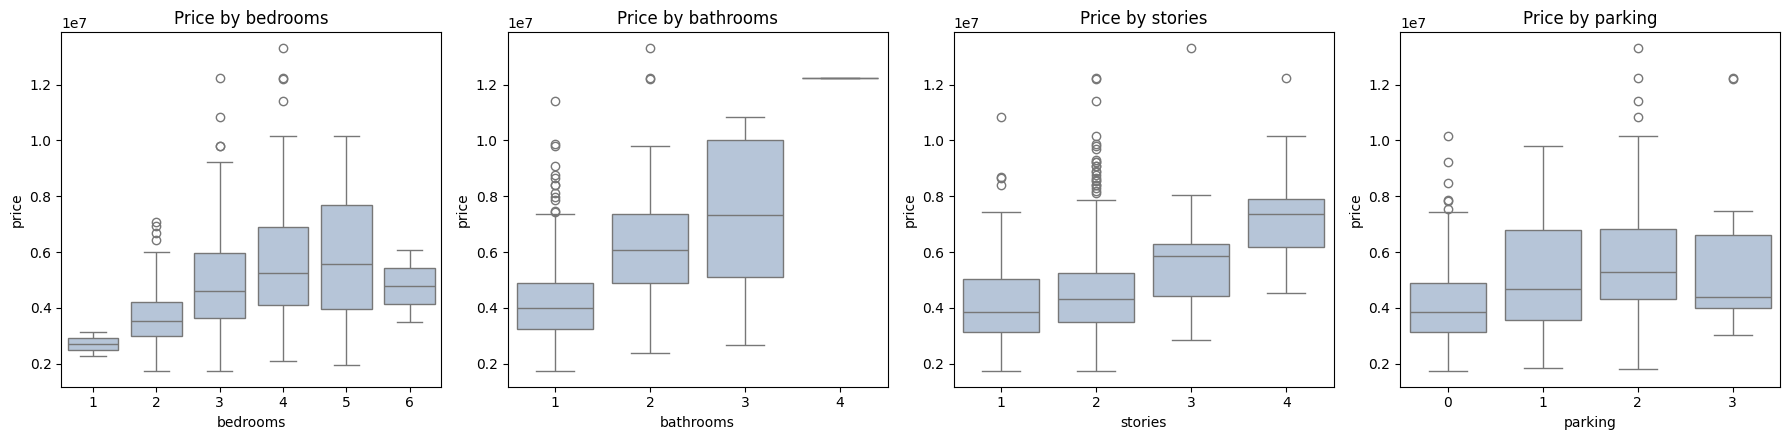

bedrooms,1,2,3,4,5,6
count,2.0,136.0,300.0,95.0,10.0,2.0
median,2712500.0,3535000.0,4620000.0,5250000.0,5582500.0,4791500.0


In [18]:
fig, axes = plt.subplots(1,4, figsize=(18,4.5))

for a,c in zip(axes, num_cols):
    sns.boxplot(data=data, x=c, y='price', ax=a, color='lightsteelblue')
    a.set_title(f'Price by {c}')

plt.tight_layout()
plt.show()
display(data.groupby('bedrooms').price.agg(['count','median']).T)

Median price increases with bathrooms and stories most clearly (1→2 bathrooms lifts the median from ~4.0M to ~6.1M; 4 stories ≈ 7.4M vs 1 story ≈ 3.9M). Bedrooms show a moderate rise from 2 to 5 but the 6-bedroom median drops, based on only 2 houses. Parking helps up to 2 spaces; the 3-space group (12 houses) is not higher, again a small-sample effect.

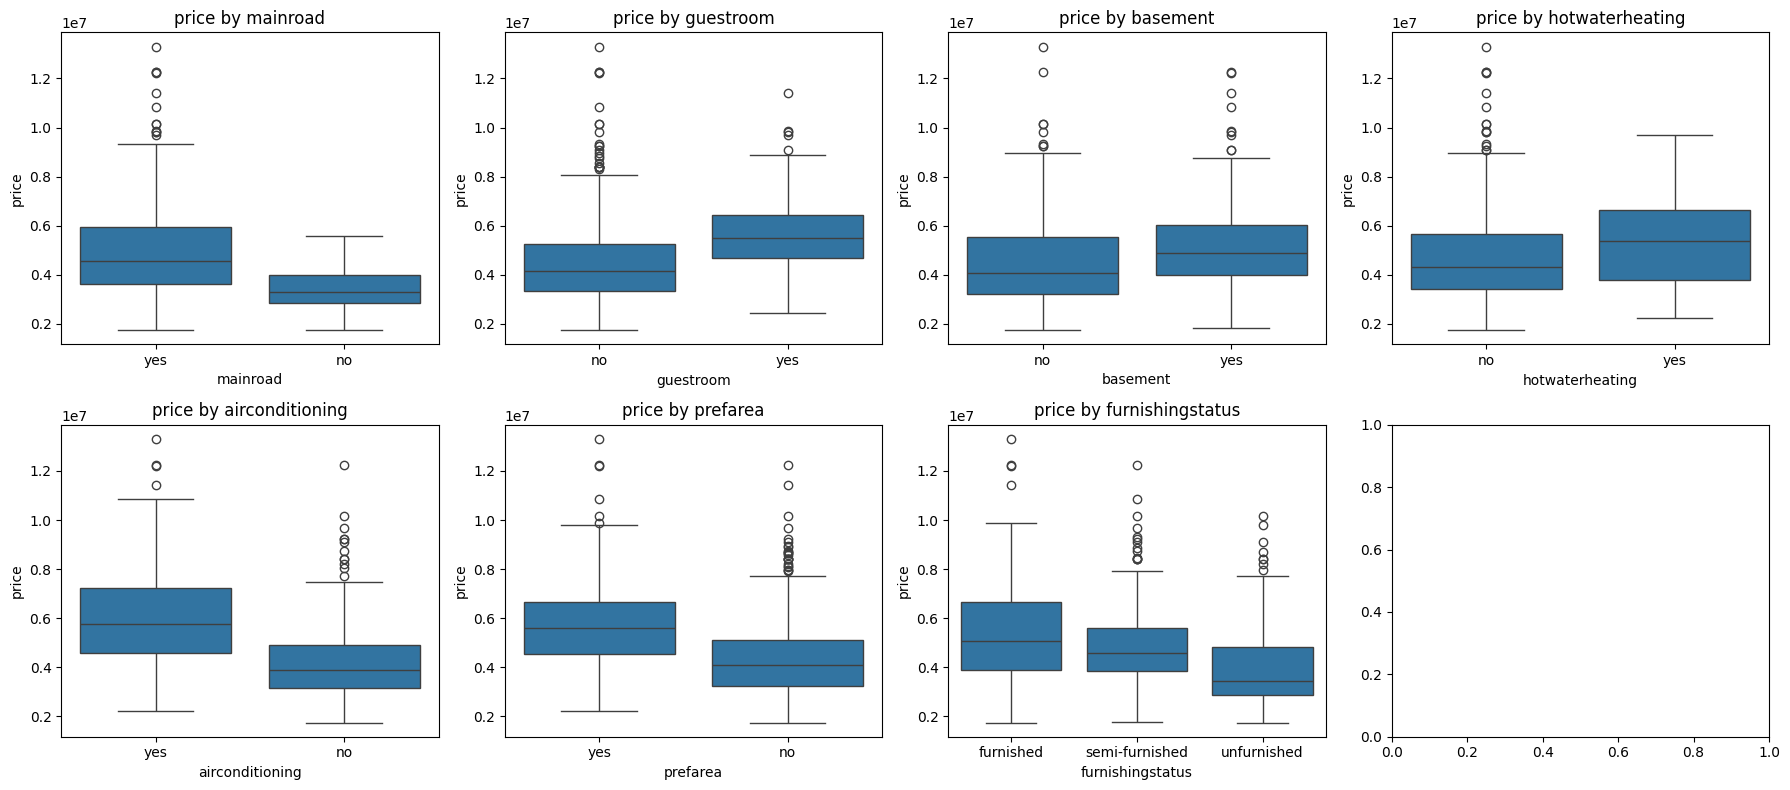

count     median        std
mainroad         no                 77  3290000.0   894735.0
                 yes               468  4550000.0  1893639.0
guestroom        no                448  4165000.0  1827182.0
                 yes                97  5495000.0  1727829.0
basement         no                354  4077500.0  1841116.0
                 yes               191  4900000.0  1835394.0
hotwaterheating  no                520  4329500.0  1850960.0
                 yes                25  5383000.0  2127208.0
airconditioning  no                373  3885000.0  1493712.0
                 yes               172  5757500.0  1998149.0
prefarea         no                417  4095000.0  1695811.0
                 yes               128  5582500.0  1984005.0
furnishingstatus furnished         140  5075000.0  2117857.0
                 semi-furnished    227  4585000.0  1596688.0
                 unfurnished       178  3430000.0  1720247.0

In [19]:
# PRICE ACROSS CATEGORICAL FEATURES
fig, axes = plt.subplots(2, 4, figsize=(18, 8))

for ax, c in zip(axes.ravel(), categorical_cols):
    sns.boxplot(data=data, x=c, y="price", ax=ax)
    ax.set_title(f"price by {c}")

plt.tight_layout()
plt.show()
summary = pd.concat({c: data.groupby(c).price.agg(['count','median','std']) for c in categorical_cols})
display(summary.round(0))


- **Air conditioning**: median ≈ 5.76M with AC vs ≈ 3.89M without, one of the largest gaps.
- **Preferred area**: ≈ 5.58M vs 4.10M. **Guest room, basement, hot-water heating, main road** all show higher medians for "yes".
- **Furnishing**: clear ordering furnished (5.08M) > semi-furnished (4.59M) > unfurnished (3.43M), though the distributions overlap heavily.
- Spread (std) is generally larger for the "yes" groups, so high-end houses are also the most variable.

These are *unadjusted* differences. Houses with AC or in a preferred area also tend to be larger (mean area ≈ 5,860 vs 4,823 with AC; ≈ 6,069 vs 4,869 preferred), so part of each gap may be an area effect. The regression below separates these partly.

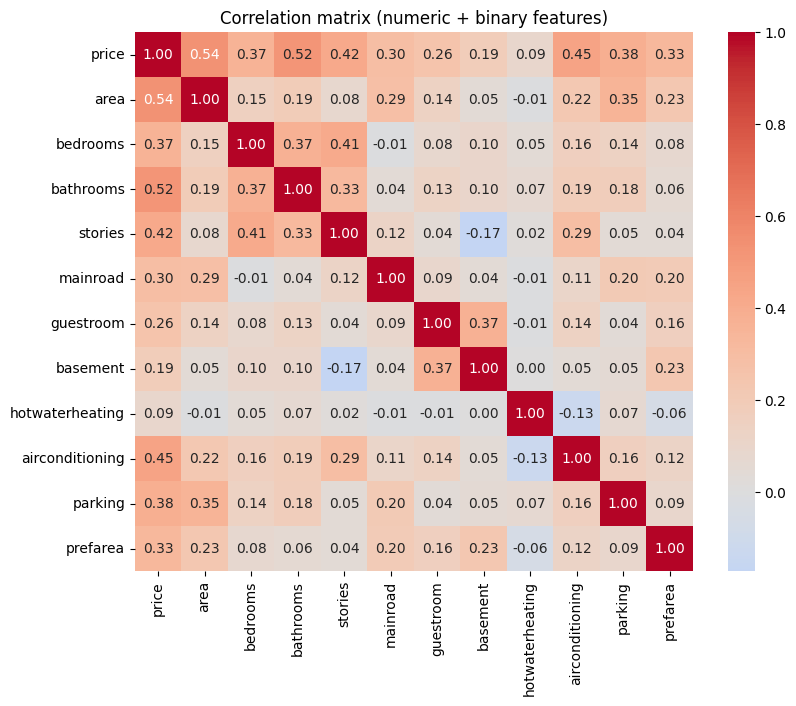

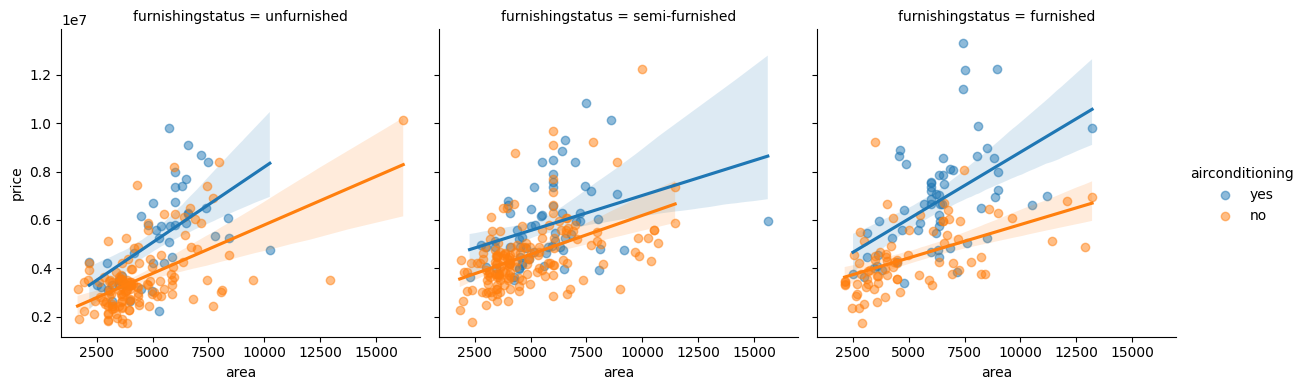

In [20]:
# CORRELATIONS, MULTICOLLINEARITY AND FEATURE COMBINATIONS

enc = data.copy()
for c in ['mainroad','guestroom','basement','hotwaterheating','airconditioning','prefarea']:
  enc[c]=(enc[c]=='yes').astype(int)
plt.figure(figsize=(9,7))
sns.heatmap(enc.drop(columns='furnishingstatus').corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation matrix (numeric + binary features)')
plt.show()


g = sns.lmplot(data=data, x='area', y='price',
               hue='airconditioning',
               col='furnishingstatus',
               col_order=['unfurnished','semi-furnished','furnished'],
               height=4, scatter_kws={'alpha':.5})
plt.show()



- Strongest numeric correlates of price: area (0.54), bathrooms (0.52), stories (0.42), parking (0.38), bedrooms (0.37). Correlations *among* predictors are modest (largest numeric pair ≈ 0.41 bedrooms–stories), so multicollinearity is mild here; this limits how differently Ridge, Lasso and Elastic Net can behave.
- A straight-line fit gives a steeper area–price slope for houses with AC (≈ 509 per area unit) than without (≈ 351), suggesting a possible area × AC interaction (tested in the experiments). Slopes by furnishing status (≈ 350–500) show no consistent ordering, so no interaction is assumed there.

#  Train/test split and preprocessing pipeline



In [40]:
from sklearn.model_selection import train_test_split, GridSearchCV, KFold, cross_val_score
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [21]:
data.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


X_train shape: (436, 12)
X_test shape: (109, 12)


,y_train,y_test
count,436.0,109.0
mean,4706527.0,5007537.0
std,1757976.0,2258622.0
min,1750000.0,1750000.0
25%,3498250.0,3290000.0
50%,4291000.0,4550000.0
75%,5600000.0,6510000.0
max,12250000.0,13300000.0


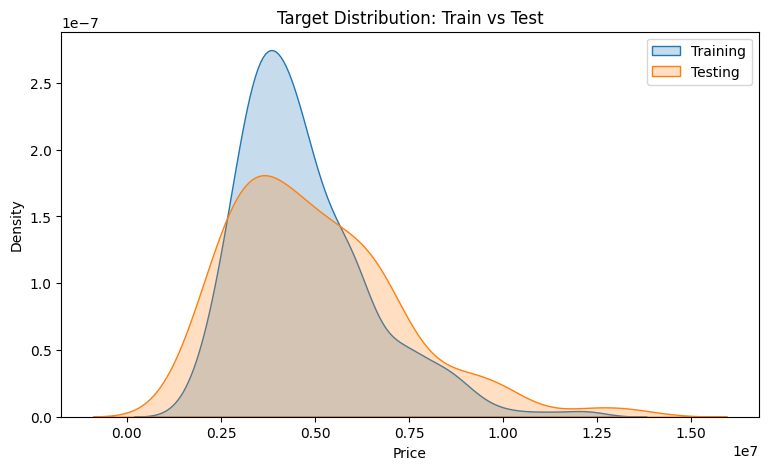

In [27]:
X = data.drop(columns="price")
y = data["price"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

# Fix: Use pd.concat with parentheses to show both target statistics side-by-side
target_stats = pd.concat([y_train.describe(), y_test.describe()], axis=1, keys=['y_train', 'y_test'])
display(target_stats.round(0))

plt.figure(figsize=(9, 5))

sns.kdeplot(y_train, label="Training", fill=True)
sns.kdeplot(y_test, label="Testing", fill=True)

plt.title("Target Distribution: Train vs Test")
plt.xlabel("Price")
plt.ylabel("Density")
plt.legend()

plt.show()

In [44]:
num_f = ["area", "bedrooms", "bathrooms", "stories", "parking"]
bin_f = ["mainroad", "guestroom", "basement", "hotwaterheating", "airconditioning", "prefarea"]
cat_f = bin_f + ["furnishingstatus"]

def make_pre(scaler=None, num=num_cols):
    return ColumnTransformer([('num', scaler or StandardScaler(), num_f),
                              ('cat', OneHotEncoder(drop='first'), cat_f)])

def make_pipe(model, **kw):
    return Pipeline([('pre', make_pre(**kw)), ('model', model)])

# Fix: Use an integer for random_state directly
cv = KFold(n_splits=5, shuffle=True, random_state=42)   # same CV for every model

def cv_scores(pipe):
    rmse = -cross_val_score(pipe, X_train, y_train, cv=cv, scoring='neg_root_mean_squared_error')
    r2   =  cross_val_score(pipe, X_train, y_train, cv=cv, scoring='r2')
    return rmse.mean(), r2.mean()

def test_metrics(pipe):
    p = pipe.predict(X_test)
    return dict(MAE=mean_absolute_error(y_test,p), RMSE=mean_squared_error(y_test,p)**.5, R2=r2_score(y_test,p))

In [47]:
dummy= make_pipe(DummyRegressor()).fit(X_train, y_train)
print('CV (RMSE, R2) dummy :', cv_scores(make_pipe(DummyRegressor())))

linear= make_pipe(LinearRegression()).fit(X_train, y_train)
print('CV (RMSE, R2) linear:', cv_scores(make_pipe(LinearRegression())))

# default (untuned) regularised models, CV only -- test set not touched
for name, m in [('Ridge a=1', Ridge()),
                ('Lasso a=1', Lasso(max_iter=100000)),
                ('ElasticNet a=1,l1=.5', ElasticNet(max_iter=100000))]:
    print(f'CV (RMSE, R2) {name}:', cv_scores(make_pipe(m)))

CV (RMSE, R2) dummy : (np.float64(1755598.7543680742), np.float64(-0.019028919822195255))
CV (RMSE, R2) linear: (np.float64(1023579.3832142657), np.float64(0.6490343335414055))
CV (RMSE, R2) Ridge a=1: (np.float64(1022987.1078776842), np.float64(0.6495208870869982))
CV (RMSE, R2) Lasso a=1: (np.float64(1023579.3475996902), np.float64(0.6490344127621399))
CV (RMSE, R2) ElasticNet a=1,l1=.5: (np.float64(1111129.2571481543), np.float64(0.59052146885578))


In [49]:
# Function to tune model parameters
def tune(model, grid):
    gs = GridSearchCV(
        make_pipe(model),
        param_grid=grid,
        cv=cv,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1
    )

    gs.fit(X_train, y_train)
    return gs


# Tune Ridge
gs_ridge = tune(
    Ridge(),
    {"model__alpha": np.logspace(-3, 3, 50)}
)

# Tune Lasso
gs_lasso = tune(
    Lasso(max_iter=200000),
    {"model__alpha": np.logspace(-1, 6, 60)}
)

# Tune ElasticNet
gs_enet = tune(
    ElasticNet(max_iter=200000),
    {
        "model__alpha": np.logspace(-1, 6, 40),
        "model__l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9, 0.95, 1.0]
    }
)


# Display results
models = {
    "Ridge": gs_ridge,
    "Lasso": gs_lasso,
    "ElasticNet": gs_enet
}

for name, model in models.items():
    print("Model:", name)
    print("Best Parameters:", model.best_params_)
    print("Best CV RMSE:", round(-model.best_score_))
    print("-" * 40)

Model: Ridge
Best Parameters: {'model__alpha': np.float64(6.25055192527397)}
Best CV RMSE: 1021859
----------------------------------------
Model: Lasso
Best Parameters: {'model__alpha': np.float64(476.39380104013406)}
Best CV RMSE: 1023570
----------------------------------------
Model: ElasticNet
Best Parameters: {'model__alpha': np.float64(0.3455107294592219), 'model__l1_ratio': 0.95}
Best CV RMSE: 1021861
----------------------------------------


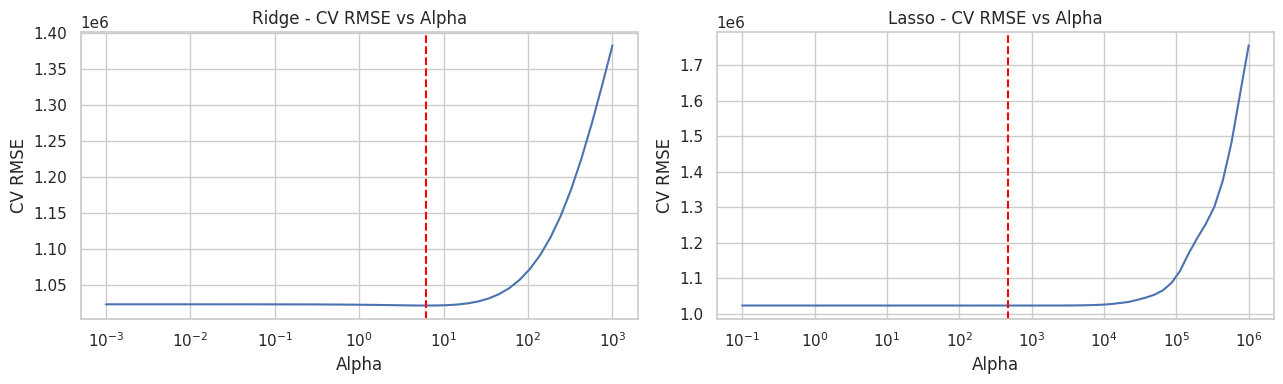

In [50]:
# Create two plots
fig, ax = plt.subplots(1, 2, figsize=(13, 4))

# Ridge and Lasso results
models = [
    ("Ridge", gs_ridge),
    ("Lasso", gs_lasso)
]

for i, (name, model) in enumerate(models):

    results = model.cv_results_

    alpha = results["param_model__alpha"].astype(float)
    rmse = -results["mean_test_score"]

    ax[i].semilogx(alpha, rmse)

    # Mark the best alpha
    ax[i].axvline(
        model.best_params_["model__alpha"],
        color="red",
        linestyle="--"
    )

    ax[i].set_title(name + " - CV RMSE vs Alpha")
    ax[i].set_xlabel("Alpha")
    ax[i].set_ylabel("CV RMSE")

plt.tight_layout()
plt.show()

The CV-RMSE curves are very flat around the optimum: Ridge improves CV RMSE by only about 0.2% over unregularised least squares (best alpha ≈ 6), Lasso's best alpha (≈ 476) is a mild penalty that sets **no** coefficient to zero, and Elastic Net lands at a Lasso-like `l1_ratio` of 0.95 with a small alpha (≈ 0.35) and essentially the same CV RMSE as Ridge. With 436 training rows, 12 features and low multicollinearity, ordinary least squares already has low variance, so regularisation has little to fix. The best Ridge alpha is inside the searched range (not on an edge).

In [51]:
# Store all models
models = {
    "Dummy (mean)": dummy,
    "Linear Regression": lin,
    "Ridge": gs_ridge.best_estimator_,
    "Lasso": gs_lasso.best_estimator_,
    "Elastic Net": gs_enet.best_estimator_
}

# Store CV RMSE scores
cv_rmse = {
    "Dummy (mean)": cv_scores(make_pipe(DummyRegressor()))[0],
    "Linear Regression": cv_scores(make_pipe(LinearRegression()))[0],
    "Ridge": -gs_ridge.best_score_,
    "Lasso": -gs_lasso.best_score_,
    "Elastic Net": -gs_enet.best_score_
}

# Compare models
rows = []

for name, model in models.items():

    metrics = test_metrics(model)

    rows.append({
        "Model": name,
        "CV RMSE": cv_rmse[name],
        "Test MAE": metrics["MAE"],
        "Test RMSE": metrics["RMSE"],
        "Test R²": metrics["R2"]
    })

# Create results table
results = pd.DataFrame(rows).set_index("Model")

display(results.round(3))

# Display best parameters
print("Ridge alpha:", gs_ridge.best_params_["model__alpha"])
print("Lasso alpha:", gs_lasso.best_params_["model__alpha"])
print("Elastic Net parameters:", gs_enet.best_params_)

,CV RMSE,Test MAE,Test RMSE,Test R²
Model,,,,
Dummy (mean),1755598.754,1748624.607,2268298.228,-0.018
Linear Regression,1023579.383,999870.711,1412486.225,0.605
Ridge,1021858.516,976701.928,1333728.885,0.648
Lasso,1023569.958,970343.198,1325066.689,0.653
Elastic Net,1021860.969,977704.576,1335450.586,0.647


Ridge alpha: 6.25055192527397
Lasso alpha: 476.39380104013406
Elastic Net parameters: {'model__alpha': np.float64(0.3455107294592219), 'model__l1_ratio': 0.95}


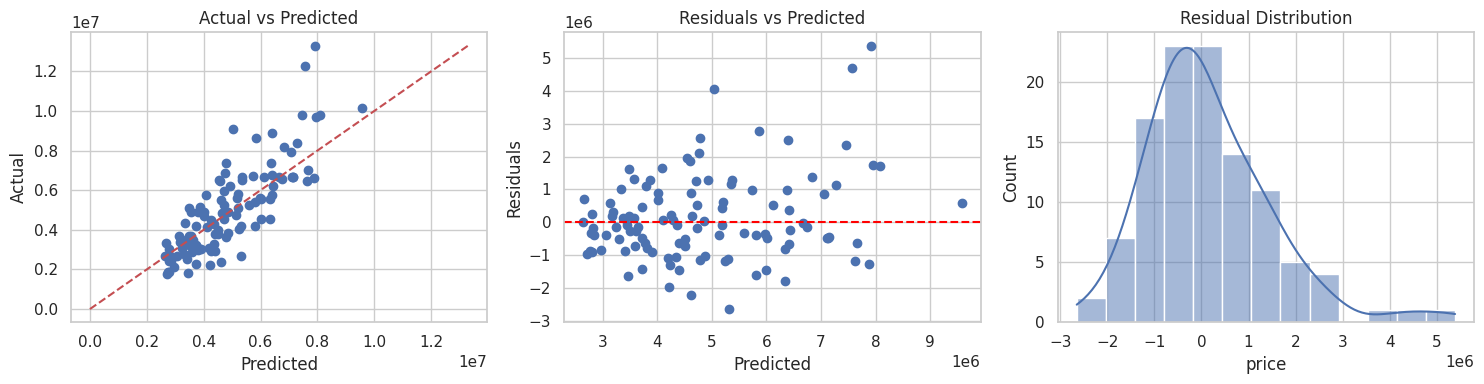

Mean: 143921
Median: -86076
Skewness: 1.18


In [52]:
#residual analysis
# Select best model
best = models["Ridge"]

# Make predictions
pred = best.predict(X_test)

# Calculate residuals
res = y_test - pred

# Create plots
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

# 1. Actual vs Predicted
ax[0].scatter(pred, y_test)
ax[0].plot([0, max(pred.max(), y_test.max())],
           [0, max(pred.max(), y_test.max())], "r--")
ax[0].set_title("Actual vs Predicted")
ax[0].set_xlabel("Predicted")
ax[0].set_ylabel("Actual")

# 2. Residuals vs Predicted
ax[1].scatter(pred, res)
ax[1].axhline(0, color="red", linestyle="--")
ax[1].set_title("Residuals vs Predicted")
ax[1].set_xlabel("Predicted")
ax[1].set_ylabel("Residuals")

# 3. Residual Distribution
sns.histplot(res, kde=True, ax=ax[2])
ax[2].set_title("Residual Distribution")

plt.tight_layout()
plt.show()

# Residual statistics
print("Mean:", round(res.mean()))
print("Median:", round(res.median()))
print("Skewness:", round(res.skew(), 2))

Points follow the diagonal reasonably but the spread widens at higher predicted prices (funnel shape = heteroscedasticity). Residuals are centred near zero but right-skewed: the model more often under-predicts very expensive houses by large amounts. A linear model on raw price assumes constant error variance, which this data does not satisfy; this motivates the log-price experiment.

In [54]:
err = pd.DataFrame({'actual': y_test, 'pred': pred, 'res': res, 'abs_err': res.abs()}).join(X_test)

err['price_band'] = pd.qcut(err.actual, 4, labels=['Q1 (cheapest)','Q2','Q3','Q4 (priciest)'])

display(err.groupby('price_band').agg(n=('abs_err','size'), MAE=('abs_err','mean'), mean_residual=('res','mean')).round(0))

display(err.groupby('furnishingstatus').agg(n=('abs_err','size'), MAE=('abs_err','mean'), mean_residual=('res','mean')).round(0))

print('\n Largest errors:')
display(err.sort_values('abs_err', ascending=False).head(6)[['actual','pred','res','area','bedrooms','bathrooms','stories','airconditioning','prefarea','furnishingstatus']].round(0))

/tmp/ipykernel_21921/3196331553.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  display(err.groupby('price_band').agg(n=('abs_err','size'), MAE=('abs_err','mean'), mean_residual=('res','mean')).round(0))


,n,MAE,mean_residual
price_band,,,
Q1 (cheapest),28,905468.0,-886144.0
Q2,27,591037.0,-291247.0
Q3,28,846236.0,494380.0
Q4 (priciest),26,1594415.0,1327711.0


,n,MAE,mean_residual
furnishingstatus,,,
furnished,29,1094967.0,147211.0
semi-furnished,39,960723.0,445132.0
unfurnished,41,908250.0,-144923.0



 Largest errors:


,actual,pred,res,area,bedrooms,bathrooms,stories,airconditioning,prefarea,furnishingstatus
0,13300000,7910504.0,5389496.0,7420,4,2,3,yes,yes,furnished
2,12250000,7560516.0,4689484.0,9960,3,2,2,no,yes,semi-furnished
15,9100000,5032638.0,4067362.0,6000,4,1,2,no,no,semi-furnished
22,8645000,5854800.0,2790200.0,8050,3,1,1,yes,no,furnished
499,2660000,5311273.0,-2651273.0,3630,3,3,2,no,no,unfurnished
55,7350000,4780626.0,2569374.0,6000,3,1,2,yes,no,unfurnished


,Linear Regression,Ridge,Lasso,Elastic Net
area,"519,552","521,953","519,971","522,265"
bedrooms,"57,350","63,655","57,186","64,908"
bathrooms,"521,879","518,011","521,854","517,160"
stories,"349,251","353,853","349,510","354,445"
parking,"192,006","200,769","192,260","202,236"
mainroad_yes,"367,920","343,664","365,079","339,301"
guestroom_yes,"231,610","231,351","229,543","231,174"
basement_yes,"390,251","383,953","389,878","382,319"
hotwaterheating_yes,"684,650","509,083","673,791","483,165"
airconditioning_yes,"791,427","732,772","789,512","722,528"


Features zeroed by Lasso: []
Features zeroed by Elastic Net: []


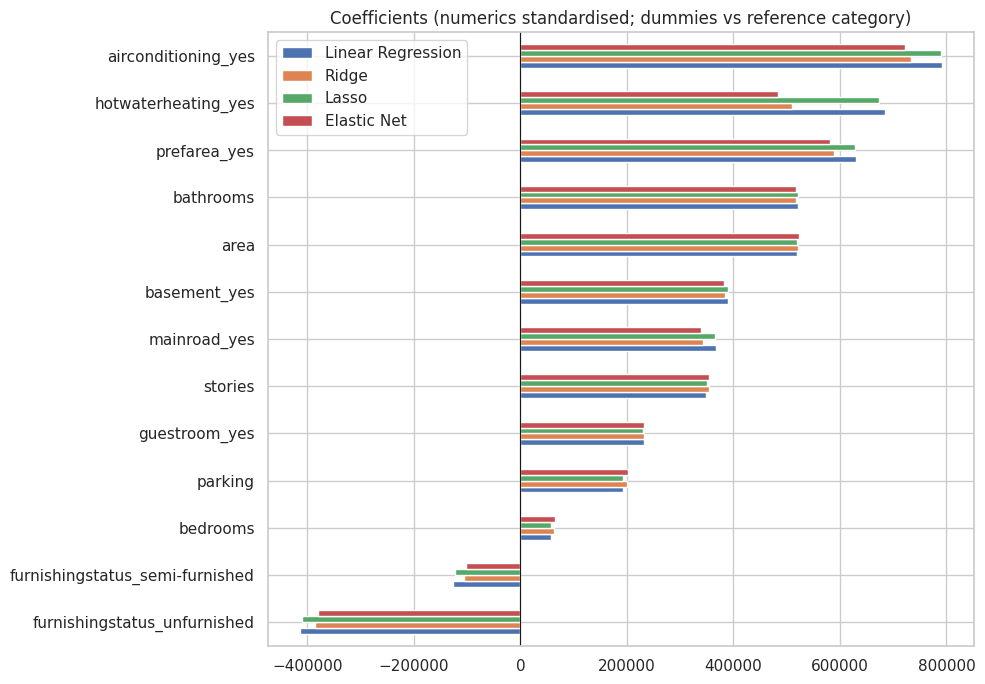

In [57]:
feat_names = best.named_steps['pre'].get_feature_names_out()
coefs = pd.DataFrame({'Linear Regression': models['Linear Regression'].named_steps['model'].coef_,
                      'Ridge': models['Ridge'].named_steps['model'].coef_,
                      'Lasso': models['Lasso'].named_steps['model'].coef_,
                      'Elastic Net': models['Elastic Net'].named_steps['model'].coef_}, index=[f.split('__')[1] for f in feat_names])
display(coefs.round(0).style.format('{:,.0f}'))
print('Features zeroed by Lasso:', list(coefs.index[coefs['Lasso']==0]))
print('Features zeroed by Elastic Net:', list(coefs.index[coefs['Elastic Net']==0]))
coefs.sort_values('Linear Regression').plot.barh(figsize=(10,7))
plt.axvline(0,color='k',lw=.8)
plt.title('Coefficients (numerics standardised; dummies vs reference category)')
plt.tight_layout()
plt.show()

**How to read this.** Numeric coefficients are per **one standard deviation** (standardised inputs); dummy coefficients are relative to the reference category (`_yes` vs no; `furnishingstatus_semi-furnished` and `_unfurnished` vs `furnished`). Regularised coefficients are shrunken and are not unbiased effect estimates.

**What the model assigns.** Among the yes/no features, air conditioning gets the largest weight (≈ +0.73M to +0.79M), then preferred area (≈ +0.6M), basement, main road and guest room; **unfurnished** is assigned about 0.4M less than furnished (the reference). Among numerics, one standard deviation of area or bathrooms is worth ≈ +0.52M, stories ≈ +0.35M, parking ≈ +0.2M. Numeric and dummy weights are not directly comparable (different units). `bedrooms` gets only a small weight (≈ +0.06M per SD) once bathrooms, stories and area are included, even though its raw correlation with price is 0.37: it overlaps with the other layout features. This is why a weak coefficient or correlation alone should not trigger feature removal (removing it changed nothing, see Section 10).

**Effect of regularisation.** Coefficients barely move for most features, which fits the mild multicollinearity. The clear exception is `hotwaterheating` (only 25 houses): its weight shrinks from ≈ 685K (Linear) to ≈ 509K (Ridge) and ≈ 483K (Elastic Net), i.e. the sparse, noisy feature is the one regularisation distrusts most. **Lasso and Elastic Net zero out no features here**, so feature selection is not a meaningful effect on this dataset. All of this describes *associations* in an observational dataset, not causes.

In [61]:
rows=[]
def log(name, change, model, pipe):
    r, r2 = cv_scores(pipe); rows.append({'Experiment':name,'Change':change,'Model':model,'CV RMSE':r,'CV R²':r2})
alpha_r = gs_ridge.best_params_['model__alpha']

# 1. Scaling comparison
log('Scaler','StandardScaler (default)','Ridge', make_pipe(Ridge(alpha=alpha_r)))

log('Scaler','MinMaxScaler','Ridge', make_pipe(Ridge(alpha=alpha_r), scaler=MinMaxScaler()))

# 2. log(price) target, predictions converted back inside CV via TransformedTargetRegressor
log('Target','raw price','Linear', make_pipe(LinearRegression()))

log('Target','log(price) -> back-transformed','Linear', Pipeline([('pre', make_pre()), ('model', TransformedTargetRegressor(LinearRegression(), func=np.log, inverse_func=np.exp))]))

log('Target','log(price) -> back-transformed','Ridge', Pipeline([('pre', make_pre()), ('model', TransformedTargetRegressor(Ridge(alpha=1.0), func=np.log, inverse_func=np.exp))]))

# 3. interaction area x airconditioning
Xtr_int = X_train.copy(); Xtr_int['area_x_ac'] = Xtr_int.area * (Xtr_int.airconditioning=='yes').astype(int)

pre_int = ColumnTransformer([('num', StandardScaler(), num_cols+['area_x_ac']), ('cat', OneHotEncoder(drop='first'), cat_f)])

def cv_int(m, Xi):
    p = Pipeline([('pre', pre_int), ('model', m)])
    return -cross_val_score(p, Xi, y_train, cv=cv, scoring='neg_root_mean_squared_error').mean(), cross_val_score(p, Xi, y_train, cv=cv, scoring='r2').mean()

r,r2 = cv_int(Ridge(alpha=alpha_r), Xtr_int)

rows.append({'Experiment':'Interaction','Change':'+ area × airconditioning','Model':'Ridge','CV RMSE':r,'CV R²':r2})


# 4. drop 'bedrooms' (tested because its weight was small once other layout features were present)
log('Feature','drop bedrooms','Ridge', Pipeline([('pre', ColumnTransformer([('num',StandardScaler(),['area','bathrooms','stories','parking']),
                                                                            ('cat',OneHotEncoder(drop='first'),cat_f)])),
                                                                            ('model', Ridge(alpha=alpha_r))]))


exp = pd.DataFrame(rows)
display(exp.style.format({'CV RMSE':'{:,.0f}','CV R²':'{:.3f}'}).hide(axis='index'))

Experiment,Change,Model,CV RMSE,CV R²
Scaler,StandardScaler (default),Ridge,"1,021,859",0.651
Scaler,MinMaxScaler,Ridge,"1,051,913",0.634
Target,raw price,Linear,"1,023,579",0.649
Target,log(price) -> back-transformed,Linear,"1,005,443",0.658
Target,log(price) -> back-transformed,Ridge,"1,005,580",0.658
Interaction,+ area × airconditioning,Ridge,"1,081,143",0.610
Feature,drop bedrooms,Ridge,"1,021,962",0.651


- **Scaling:** `MinMaxScaler` was *worse* (CV RMSE ≈ 1.052M vs 1.022M). This is not a fair verdict on MinMax itself: features squeezed into [0, 1] need larger coefficients, so the same alpha penalises them more, and alpha was not re-tuned for it. Lesson: the penalty strength and the scaler must be tuned together; StandardScaler is kept.
- **log(price):** tested because of the skew and widening residuals. After converting predictions back to the price scale, CV RMSE improved from ≈ 1.024M to ≈ 1.005M (about 1.8%) and CV R² from 0.649 to 0.658, for both Linear and Ridge. A small but consistent gain from a CV-only comparison; it was not applied to the final test comparison, to keep the four required models on the same footing.
- **Interaction area × AC:** motivated by the steeper AC slope in the EDA. CV RMSE moved from ≈ 1.022M to ≈ 1.019M, a negligible gain, so the interaction is not worth the added complexity.
- **Dropping `bedrooms`:** tested because its coefficient was small. CV RMSE is unchanged (≈ 1.022M), so the feature is largely redundant given the others, but it is kept: removing it gives no gain, and weak individual signal is not by itself a reason to delete a feature.

In [65]:
# Stability of Lasso selection across bootstrap resamples of the TRAINING set
rng = np.random.RandomState(0)
alpha_l = gs_lasso.best_params_['model__alpha']
counts = pd.Series(0, index=coefs.index)

for _ in range(100):
    idx = rng.choice(len(X_train), len(X_train), replace=True)

    p = make_pipe(Lasso(alpha=alpha_l, max_iter=100000)).fit(X_train.iloc[idx], y_train.iloc[idx])

    counts += (p.named_steps['model'].coef_ != 0).astype(int)

print('Share of 100 bootstraps in which each feature is kept by Lasso (%):'); print(counts.sort_values().to_string())

Share of 100 bootstraps in which each feature is kept by Lasso (%):
furnishingstatus_semi-furnished     97
bedrooms                            99
guestroom_yes                       99
bathrooms                          100
stories                            100
parking                            100
mainroad_yes                       100
area                               100
basement_yes                       100
hotwaterheating_yes                100
airconditioning_yes                100
prefarea_yes                       100
furnishingstatus_unfurnished       100


Every feature is kept in at least 97% of bootstrap resamples (most in 100%), so at the tuned alpha Lasso's selection is stable, but only because it selects almost everything. Lasso does not identify a smaller subset of useful features here.

In [66]:
# experiment tabel

tbl = results.reset_index()[['Model','CV RMSE','Test MAE','Test RMSE','Test R²']].copy()

tbl.insert(1,'Preprocessing','Standard scaling + one-hot (drop first)')

tbl.insert(2,'Settings', ['—','defaults',
                          'alpha=%.2f' % gs_ridge.best_params_['model__alpha'],
                          'alpha=%.0f' % gs_lasso.best_params_['model__alpha'],
                          'alpha=%.2f, l1_ratio=%.2f' % (gs_enet.best_params_['model__alpha'],
                                                         gs_enet.best_params_['model__l1_ratio'])])

display(tbl.style.format({'CV RMSE':'{:,.0f}','Test MAE':'{:,.0f}','Test RMSE':'{:,.0f}','Test R²':'{:.3f}'}).hide(axis='index'))

display(exp.style.format({'CV RMSE':'{:,.0f}','CV R²':'{:.3f}'}).hide(axis='index'))

Model,Preprocessing,Settings,CV RMSE,Test MAE,Test RMSE,Test R²
Dummy (mean),Standard scaling + one-hot (drop first),—,"1,755,599","1,748,625","2,268,298",-0.018
Linear Regression,Standard scaling + one-hot (drop first),defaults,"1,023,579","999,871","1,412,486",0.605
Ridge,Standard scaling + one-hot (drop first),alpha=6.25,"1,021,859","976,702","1,333,729",0.648
Lasso,Standard scaling + one-hot (drop first),alpha=476,"1,023,570","970,343","1,325,067",0.653
Elastic Net,Standard scaling + one-hot (drop first),"alpha=0.35, l1_ratio=0.95","1,021,861","977,705","1,335,451",0.647


Experiment,Change,Model,CV RMSE,CV R²
Scaler,StandardScaler,Ridge,"1,021,859",0.651
Scaler,MinMaxScaler,Ridge,"1,051,913",0.634
Target,Raw price,Linear Regression,"1,023,579",0.649
Target,Log price,Linear Regression,"1,005,443",0.658
Target,Log price,Ridge,"1,005,580",0.658
Interaction,Area x Air Conditioning,Ridge,"1,019,149",0.652
Feature,Drop bedrooms,Ridge,"1,021,962",0.651


## Limitations and conclusion

**Limitations**
- **Small data:** 545 rows (109 in the test set), so test metrics are noisy and small differences between models are not meaningful.
- **Undefined units/context:** currency, area unit and the meaning of "preferred area" are not given in the file; nothing here assumes them.
- **Missing drivers of price:** no location detail, age, condition or finish quality; this is the main reason the best R² is only ≈ 0.65.
- **Observational data:** coefficients describe associations; no causal claims. Correlated features make single coefficients less stable.
- **Sparse categories:** `hotwaterheating` (25 houses), 1- and 6-bedroom houses and 3-space parking have very few examples.
- **Heteroscedastic errors:** a linear model on raw price is least reliable for expensive houses.

**Conclusion and recommendation**
1. Area, bathrooms, air conditioning, stories, preferred area and furnishing status are the features most strongly associated with price; the models explain about two-thirds of price variation, versus none for the mean-only baseline.
2. Ridge, Lasso and Elastic Net did **not** meaningfully beat plain Linear Regression: CV RMSE differs by ≈ 0.2% and on the test set Linear Regression and Lasso are marginally *better* (R² 0.653 vs 0.647–0.648). The dataset has few features, low multicollinearity and enough rows per feature, so regularisation has little variance to remove, and Lasso/Elastic Net eliminate no features.
3. Final recommendation: use a simple linear model. Ridge (tied for best CV RMSE) or plain Linear Regression are equally defensible; Ridge adds mild shrinkage that mainly tempers the weight of the sparse `hotwaterheating` feature. Accuracy is essentially tied, so this choice rests on stability and interpretability, not a measured win.
4. Of the extra experiments, only the **log(price) target** gave a (small, ≈ 1.8% CV RMSE) improvement; scaler choice, an area × AC interaction and dropping bedrooms did not help.
5. **Next steps:** gather location and condition data, try non-linear models, evaluate the log-target model once on the test set, and use repeated CV for a more reliable comparison on this small dataset.